In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import swc.aeon.io.api as aeon
from dotmap import DotMap
from swc.aeon.io.video import frames
from swc.aeon.schema.streams import Device

from open_rigs.io.streams import csv, harp_device, raw_video

In [11]:
root = Path(r"C:/Users/Saleem Lab/source/repos/hf-visual/temp_data/sub-M26031/ses-20261008_1_date-2026-10-08T15-12-29")

experiment = DotMap(
    [
        Device("Arduino", csv(columns=("encoder_count", "lick_count_left", "lick_count_right", "last_sync_pulse_time", "photodiode", "current_ms"))),
        Device("ArduinoPhotodiode", csv(columns=("photodiode", "sync_val"))),
        Device("Texture", csv(columns=("texture"))),
        Device("VideoData", raw_video()),
    ]
)

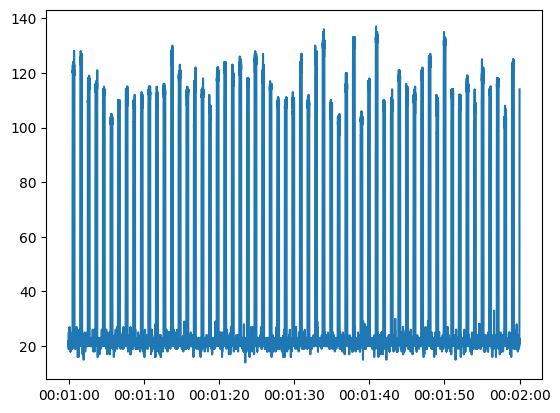

In [ ]:
arduino_data = aeon.load(root, experiment.Arduino)
arduino_data.head()
arduino_data_photodiode = aeon.load(root, experiment.ArduinoPhotodiode)

start = aeon.to_datetime(60.0)
end = aeon.to_datetime(70.0)
plt.figure()
plt.plot(arduino_data_photodiode.photodiode[start:end])